# Portable features: can the Stage 3 recipe work without M5-specific inputs? (CA_1 / FOODS)

The Reference model (`m5-v1`) uses inputs that only exist in the M5 data: M5 item/department/store IDs, M5 day and week numbers, US sporting and cultural events, and the California SNAP flag. A business using the app has none of these, so own-data workspaces use the **`portable-v1`** schema instead (design document §10.3):

| `m5-v1` | `portable-v1` |
| --- | --- |
| `id`, `item_id`, `dept_id`, `cat_id`, `store_id`, `state_id` | `product_id`, `category`, `store_id` |
| `d_num`, `wm_yr_wk`, `year_num` | `days_since_history_start`, `year_num` |
| M5 `event_*` columns | public holidays from the `holidays` package (`holiday_name`, `is_holiday`) |
| `snap` | dropped |
| weekly `sell_price` | daily price, last known price carried forward |

The lags, rolling windows, calendar fields and LightGBM settings are unchanged.

This notebook answers two questions:

1. **How much accuracy does dropping the M5-specific inputs cost?** Train `portable-v1` on the full CA_1 FOODS history with exactly the M5 windows (train ≤ `d_1885`, early stopping on `d_1886`–`d_1913`, refit, backtest `d_1914`–`d_1941`) and compare it with `m5-v1`.
2. **How much data does a small business need?** Simulate smaller stores by sampling products and truncating history, run the real own-data training pipeline (`mlengine.pipelines.own_data.train_own_data`, which includes the beat-the-baseline gate), and see when the gate is reliably passed. This sets the provisional eligibility thresholds in `config.OWN_DATA_ELIGIBILITY`.

In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# The notebooks live in notebooks/; mlengine lives in the project root.
projectRoot = Path.cwd().resolve()
while not (projectRoot / "mlengine").is_dir() and projectRoot != projectRoot.parent:
    projectRoot = projectRoot.parent
sys.path.insert(0, str(projectRoot))
figuresDir = projectRoot / "reports" / "figures"
tablesDir = projectRoot / "reports" / "tables"
figuresDir.mkdir(parents=True, exist_ok=True)
tablesDir.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore", category=DeprecationWarning)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

import mlengine
from mlengine import config
print(f"mlengine {mlengine.__version__} from {projectRoot}")

mlengine 0.1.0 from /home/karanei/SemProject_MLEngine


In [2]:
import json
from mlengine.pipelines import own_data

referenceDir = projectRoot / "data" / "processed" / "reference"
if not (referenceDir / "sales_daily.parquet").is_file():
    from mlengine.pipelines.reference_export import export_reference
    export_reference()
salesDaily = pd.read_parquet(referenceDir / "sales_daily.parquet")
products = pd.read_parquet(referenceDir / "products.parquet")
history = salesDaily.merge(products[["product_id", "category"]], on="product_id")
print(f"Canonical rows: {len(history):,}  ({history['product_id'].nunique():,} products, "
      f"{history['date'].min()} to {history['date'].max()})")

Canonical rows: 2,789,217  (1,437 products, 2011-01-29 to 2016-05-22)


## 1. Full CA_1 FOODS: `portable-v1` versus `m5-v1`

`train_own_data` measures its windows back from the last history day (2016-05-22). That makes them exactly the M5 windows: backtest = the last 28 days, validation = the 28 days before that. The holiday calendar is US / California.

In [3]:
fullResult = own_data.train_own_data(history, "ca1-portable-experiment", country="US", subdivision="CA",
                                     register=False)
m5Backtest = json.loads((projectRoot / "models" / "m5-ca1-foods" / "1.1.0-bt" / "backtest" / "summary.json").read_text())
comparison = pd.DataFrame([
    {"model": "m5-v1 (Reference, Stage 3)", **{k: m5Backtest["ai"][k] for k in ["rmse", "mae", "wape"]}},
    {"model": "portable-v1", **{k: fullResult["backtest"]["ai"][k] for k in ["rmse", "mae", "wape"]}},
    {"model": "Naive (last value)", **{k: fullResult["backtest"]["naive_last_value"][k] for k in ["rmse", "mae", "wape"]}},
]).set_index("model")
display(comparison)
print(f"Trees (early-stopped): {fullResult['bestIteration']}; gate passed: {fullResult['gate']['passed']}")
change = 100 * (comparison.loc["portable-v1"] / comparison.loc["m5-v1 (Reference, Stage 3)"] - 1)
print("portable-v1 vs m5-v1 (% change):", change.round(2).to_dict())

,rmse,mae,wape
model,,,
"m5-v1 (Reference, Stage 3)",2.377,1.377,0.610
portable-v1,2.380,1.379,0.611
Naive (last value),3.219,1.729,0.766


Trees (early-stopped): 69; gate passed: True
portable-v1 vs m5-v1 (% change): {'rmse': 0.13, 'mae': 0.16, 'wape': 0.16}


## 2. Simulated smaller stores

For each combination of **number of products** and **days of history** (ending 2016-05-22), sample products at random (3 seeds), then run the own-data pipeline with the eligibility rules switched off. Record whether the gate passes and how the AI model's backtest RMSE compares with naive.

Small samples make the 28-day backtest noisy, so the useful signal is the *pass rate* and the *typical improvement*, not any single run.

In [4]:
import time

productCounts = [10, 25, 50, 100]
historyLengths = [90, 120, 180, 365]
seeds = [0, 1, 2]
noRules = {"minProducts": 1, "minHistoryDaysPerProduct": 1, "minStoreHistoryDays": 1, "minObservedProductDays": 1}

allProducts = history["product_id"].drop_duplicates().to_numpy()
lastDate = pd.Timestamp(history["date"].max())
historyDates = pd.to_datetime(history["date"])
runs = []
started = time.time()
for nProducts in productCounts:
    for nDays in historyLengths:
        windowStart = lastDate - pd.Timedelta(days=nDays - 1)
        inWindow = history[historyDates >= windowStart]
        for seed in seeds:
            chosen = np.random.default_rng(seed).choice(allProducts, nProducts, replace=False)
            sample = inWindow[inWindow["product_id"].isin(chosen)]
            result = own_data.train_own_data(sample, "sim", "US", "CA", rules=noRules, register=False)
            row = {"products": nProducts, "history_days": nDays, "seed": seed, "status": result["status"],
                   "product_days": int(len(sample))}
            if "backtest" in result:
                row.update(ai_rmse=result["backtest"]["ai"]["rmse"], naive_rmse=result["backtest"]["naive_last_value"]["rmse"],
                           ai_mae=result["backtest"]["ai"]["mae"], naive_mae=result["backtest"]["naive_last_value"]["mae"],
                           trees=result["bestIteration"], gate=result["gate"]["passed"])
            runs.append(row)
simulation = pd.DataFrame(runs)
simulation["rmse_vs_naive"] = 1 - simulation["ai_rmse"] / simulation["naive_rmse"]
print(f"{len(simulation)} training runs in {time.time() - started:.0f}s")
simulation.to_csv(tablesDir / "portable_small_store_simulation.csv", index=False)

48 training runs in 166s


In [5]:
passRate = simulation.pivot_table(index="products", columns="history_days", values="gate", aggfunc="mean")
improvement = simulation.pivot_table(index="products", columns="history_days", values="rmse_vs_naive", aggfunc="median")
print("Share of runs that passed the gate (AI beats naive on both RMSE and MAE)")
display(passRate)
print("Median RMSE improvement over naive (1 - AI/naive)")
display((100 * improvement).round(1))
statusCounts = simulation.groupby(["history_days", "status"]).size().unstack(fill_value=0)
display(statusCounts)

Share of runs that passed the gate (AI beats naive on both RMSE and MAE)


history_days,90,120,180,365
products,,,,
10,0.333,0.333,1.000,1.000
25,0.667,0.667,0.667,1.000
50,1.000,1.000,1.000,1.000
100,1.000,1.000,1.000,1.000


Median RMSE improvement over naive (1 - AI/naive)


history_days,90,120,180,365
products,,,,
10,17.700,18.100,20.800,21.000
25,16.400,23.400,21.500,25.000
50,23.200,25.900,27.700,27.500
100,15.600,19.600,21.800,25.600


status,GATE_FAILED,GATE_PASSED
history_days,,
90,3,9
120,3,9
180,1,11
365,0,12


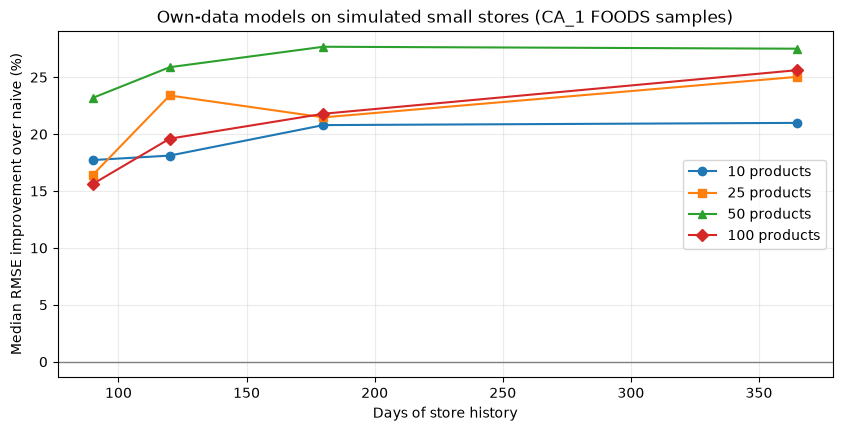

In [6]:
figure, axis = plt.subplots(figsize=(10, 4.5))
markers = {10: "o", 25: "s", 50: "^", 100: "D"}
for nProducts in productCounts:
    subset = improvement.loc[nProducts]
    axis.plot(subset.index, 100 * subset.to_numpy(), marker=markers[nProducts], label=f"{nProducts} products")
axis.axhline(0, color="grey", linewidth=1)
axis.set_xlabel("Days of store history")
axis.set_ylabel("Median RMSE improvement over naive (%)")
axis.set_title("Own-data models on simulated small stores (CA_1 FOODS samples)")
axis.legend()
figure.savefig(figuresDir / "portable_small_store_simulation.png", dpi=120, bbox_inches="tight")
plt.show()

## Conclusions

**1. Dropping the M5-specific inputs costs almost nothing.** On the same CA_1 FOODS windows, `portable-v1` scores backtest RMSE 2.380 / MAE 1.379 against 2.377 / 1.377 for `m5-v1`, about 0.1–0.2% worse. Both are far ahead of naive (3.219). The M5 IDs, the M5 day numbering, the US event calendar and SNAP carry very little signal that the lags and rolling statistics don't already capture. This agrees with the Stage 7 finding that the recipe is close to saturating what the sales history offers. **The recipe transfers. The M5 weights don't need to.**

**2. Small stores: the gate passes reliably from about 4,500 product-days.**

| Products × history | Gate pass rate | Median RMSE gain vs naive |
| --- | --- | --- |
| 10 × 90–120 days | 1 / 3 | 18% |
| 10 × 180–365 days | 3 / 3 | 21% |
| 25 × 90–180 days | 2 / 3 | 16–23% |
| 50+ × any length ≥ 90 days | 3 / 3 | 16–28% |

- **Every gate failure was on MAE, never RMSE.** The Tweedie model predicts the *expected* value. For products that often sell zero, the naive "same as yesterday" forecast can have a slightly lower *absolute* error while having a much larger squared error. Keeping MAE in the gate is deliberately conservative: a business should only see the AI forecast where it is better on both measures.
- The median RMSE gain is 16–28% everywhere, so when the gate fails it is by a small margin on a small, noisy 28-day backtest.

**Thresholds adopted in `config.OWN_DATA_ELIGIBILITY`** (eligibility only decides whether training is *attempted*; the gate still decides whether the model is *used*):

- at least 10 products with 21+ days of history,
- at least 120 days of store history (enough for training, a 28-day validation window and a 28-day backtest),
- at least **4,500** observed product-days (changed from the provisional 5,000). Every simulated store with 4,500+ product-days and 120+ days passed the gate in at least 2 of 3 runs, and every one with 6,000+ passed in all 3. The only configurations that passed just 1 in 3 (10 products × 90–120 days, 900–1,200 product-days) fall well below it. Some smaller stores (10 products × 180+ days) also passed, so the threshold is conservative; the gate remains the real safeguard.

**Caveats.** These simulations sample products from one dense US grocery store. A Kenyan retailer's demand may be sparser or more seasonal, which is why every own-data model must still pass its own backtest gate before the app shows it.
